# SHAP Explainability

In [2]:
%pip install matplotlib
%pip install shap

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 4.2 MB/s eta 0:00:01
   ----------------------------- ---------- 1.8/2.5 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 4.9 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------- ----------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 5.2 MB/s  0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
%pip install torch 

  Using cached torch-2.14.1-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
Using cached torch-2.14.1-cp312-cp312-win_amd64.whl (124.1 MB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ---------------------------------------- 0/6 [networkx]
   ----------------------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
%pip install transformers

  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached regex-2026.9.29-cp312-cp312-win_amd64.whl.metadata (41 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    pipeline,
)

In [9]:

# Local project path
PROJECT_ROOT = Path(r"D:\HINSAFE")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import basic_clean


print("Python executable:", sys.executable)
print("Project root:", PROJECT_ROOT)
print("GPU available:", torch.cuda.is_available())

Python executable: d:\HINSAFE\.venv\Scripts\python.exe
Project root: D:\HINSAFE
GPU available: False


In [10]:
TEST_PATH = PROJECT_ROOT / "datasets" / "processed" / "test_split.csv"
MODEL_DIR = PROJECT_ROOT / "saved_models" / "muril"
SHAP_DIR = PROJECT_ROOT / "results" / "shap_plots"

SHAP_DIR.mkdir(parents=True, exist_ok=True)

MAX_LENGTH = 128
NUM_TEST_SAMPLES = 10
TOP_N_WORDS = 5


In [11]:
if not TEST_PATH.exists():
    raise FileNotFoundError(
        f"Test dataset was not found: {TEST_PATH}"
    )

if not MODEL_DIR.exists():
    raise FileNotFoundError(
        f"MuRIL model directory was not found: {MODEL_DIR}"
    )

required_model_files = [
    MODEL_DIR / "config.json",
    MODEL_DIR / "model.safetensors",
    MODEL_DIR / "tokenizer.json",
]

missing_files = [
    str(file)
    for file in required_model_files
    if not file.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following MuRIL files are missing:\n"
        + "\n".join(missing_files)
    )


In [12]:

print("Model folder:", MODEL_DIR)
print("Test file:", TEST_PATH)
print("SHAP output folder:", SHAP_DIR)

Model folder: D:\HINSAFE\saved_models\muril
Test file: D:\HINSAFE\datasets\processed\test_split.csv
SHAP output folder: D:\HINSAFE\results\shap_plots


In [13]:
id2label = {
    0: "NOT_OFFENSIVE",
    1: "OFFENSIVE",
}

label2id = {
    "NOT_OFFENSIVE": 0,
    "OFFENSIVE": 1,
}

tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR),
    id2label=id2label,
    label2id=label2id,
    local_files_only=True,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)
model.eval()

print("MuRIL model and tokenizer loaded successfully.")
print("Using device:", device)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 400.36it/s]

MuRIL model and tokenizer loaded successfully.
Using device: cpu


In [14]:
pipeline_device = 0 if torch.cuda.is_available() else -1

prediction_pipeline = pipeline(
    task="text-classification",
    model=model,
    tokenizer=tokenizer,
    device=pipeline_device,
    top_k=None,
    truncation=True,
    max_length=MAX_LENGTH,
)

test_output = prediction_pipeline(
    ["tu bilkul bekaar hai mar ja"]
)

print(test_output)

[[{'label': 'NOT_OFFENSIVE', 'score': 0.8137403130531311}, {'label': 'OFFENSIVE', 'score': 0.18625973165035248}]]


In [15]:
explainer = shap.Explainer(prediction_pipeline)

print("SHAP explainer created successfully.")

d:\HINSAFE\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


SHAP explainer created successfully.


In [28]:
demo_comments = [
    "tujhe mar  dunga",
    "thank you so much bhai",
    "kal milte hain, take care",
    "tu bekaar nahi hai",
]

demo_cleaned = [
    basic_clean(comment)
    for comment in demo_comments
]

demo_shap_values = explainer(demo_cleaned)

In [29]:
first_explanation = demo_shap_values[0, :, "OFFENSIVE"]

print("Tokens:", list(first_explanation.data))
print("SHAP values:", np.round(first_explanation.values, 3))

Tokens: ['', 'tu', 'jhe ', 'mar ', 'dung', 'a', '']
SHAP values: [ 0.     0.085  0.091 -0.027  0.336 -0.086  0.   ]


In [30]:
# word-level contributions can be obtained by merging subword tokens

def merge_into_words(tokens, values):

    words = []
    scores = []

    current_word = ""
    current_score = 0.0

    for token, value in zip(tokens, values):
        token = str(token)
        value = float(value)

        if not token.strip():
            continue

        # A leading space usually indicates a new word.
        if token[0].isspace() and current_word:
            words.append(current_word)
            scores.append(current_score)

            current_word = ""
            current_score = 0.0

        current_word += token.strip()
        current_score += value

        # Some tokenizers mark the end of a word with a space.
        if token.endswith(" "):
            words.append(current_word)
            scores.append(current_score)

            current_word = ""
            current_score = 0.0

    if current_word:
        words.append(current_word)
        scores.append(current_score)

    return words, scores

In [31]:
def get_flagged_words(explanation, top_n=TOP_N_WORDS):
    """
    Return the strongest words contributing toward OFFENSIVE.
    """

    words, scores = merge_into_words(
        explanation.data,
        explanation.values,
    )

    positive_pairs = [
        (word, score)
        for word, score in zip(words, scores)
        if score > 0
    ]

    positive_pairs.sort(
        key=lambda pair: pair[1],
        reverse=True,
    )

    return {
        word: round(score, 3)
        for word, score in positive_pairs[:top_n]
    }

In [34]:
def show_demo_explanations(
    comments,
    cleaned_comments,
    shap_values,
    top_n=TOP_N_WORDS,
):
    
    results = []

    for index, comment in enumerate(comments):
        explanation = shap_values[
            index,
            :,
            "OFFENSIVE",
        ]

        prediction_output = prediction_pipeline(
            [cleaned_comments[index]]
        )[0]

        probabilities = {
            item["label"]: float(item["score"])
            for item in prediction_output
        }

        predicted_label = max(
            probabilities,
            key=probabilities.get,
        )

        offensive_probability = probabilities.get(
            "OFFENSIVE",
            0.0,
        )

        flagged_words = get_flagged_words(
            explanation,
            top_n=top_n,
        )

        result = {
            "comment": comment,
            "prediction": predicted_label,
            "offensive_probability": round(
                offensive_probability,
                3,
            ),
            "flagged_words": flagged_words,
        }

        results.append(result)

        print(comment)
        print(
            "Prediction:",
            predicted_label,
            f"(offensive probability: "
            f"{offensive_probability:.3f})",
        )
        print("Flagged words:", flagged_words)

        if not flagged_words:
            print(
                "No words pushed the prediction "
                "toward OFFENSIVE."
            )

        print()

    return results

In [35]:
demo_results = show_demo_explanations(
    comments=demo_comments,
    cleaned_comments=demo_cleaned,
    shap_values=demo_shap_values,
)

print("Finished.")

tujhe mar  dunga
Prediction: OFFENSIVE (offensive probability: 0.807)
Flagged words: {'dunga': 0.25, 'tujhe': 0.176}

thank you so much bhai
Prediction: NOT_OFFENSIVE (offensive probability: 0.188)
Flagged words: {}
No words pushed the prediction toward OFFENSIVE.

kal milte hain, take care
Prediction: NOT_OFFENSIVE (offensive probability: 0.189)
Flagged words: {}
No words pushed the prediction toward OFFENSIVE.

tu bekaar nahi hai
Prediction: NOT_OFFENSIVE (offensive probability: 0.187)
Flagged words: {}
No words pushed the prediction toward OFFENSIVE.

Finished.


In [36]:
shap.plots.text(
    demo_shap_values[0, :, "OFFENSIVE"]
)

In [37]:
def save_bar_chart(
    explanation,
    title,
    save_path,
    top_n=10,
):
    """Save positive and negative SHAP contributions as a bar chart."""

    words, scores = merge_into_words(
        explanation.data,
        explanation.values,
    )

    pairs = sorted(
        zip(words, scores),
        key=lambda pair: abs(pair[1]),
        reverse=True,
    )[:top_n]

    # Reverse so the strongest item appears at the top.
    pairs.reverse()

    labels = [word for word, _ in pairs]
    values = [score for _, score in pairs]

    colors = [
        "tab:red" if value > 0 else "tab:blue"
        for value in values
    ]

    plt.figure(figsize=(8, 5))
    plt.barh(labels, values, color=colors)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel(
        "SHAP value "
        "(red = toward offensive, blue = away)"
    )
    plt.title(title)
    plt.tight_layout()

    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    print("Saved plot to:", save_path)

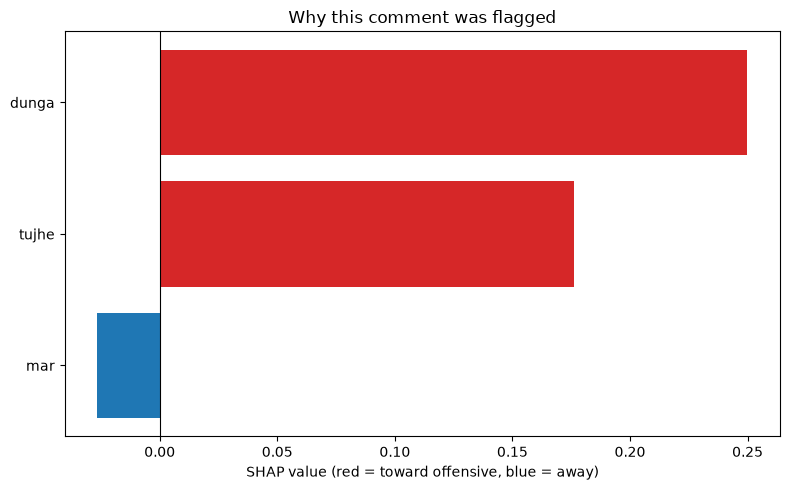

Saved plot to: D:\HINSAFE\results\shap_plots\demo_bar_chart.png


In [38]:
save_bar_chart(
    explanation=demo_shap_values[
        0,
        :,
        "OFFENSIVE",
    ],
    title="Why this comment was flagged",
    save_path=SHAP_DIR / "demo_bar_chart.png",
)

In [39]:
# severity score 
def calculate_severity(offensive_probability):
    return int(round(float(offensive_probability) * 100))


def severity_band(score):

    if score < 40:
        return "SAFE"

    if score < 70:
        return "OFFENSIVE"

    return "HATE SPEECH"

In [40]:
CATEGORY_LEXICON = {
    "cyberbullying": [
        "bekaar",
        "ghatiya",
        "nalayak",
        "pagal",
    ],
    "threat": [
        "mar ja",
        "maar dunga",
        "khatam kar dunga",
        "jaan se",
    ],
    "misogyny": [],
    "communal": [],
    "casteist": [],
}


def detect_categories(
    clean_text,
    lexicon=CATEGORY_LEXICON,
):
    """Return categories whose phrases appear in the cleaned text."""

    padded_text = f" {clean_text.lower()} "
    found_categories = []

    for category, phrases in lexicon.items():
        for phrase in phrases:
            phrase = phrase.lower().strip()

            if f" {phrase} " in padded_text:
                found_categories.append(category)
                break

    return found_categories

In [41]:
def get_offensive_probability(text):
    """Return MuRIL's probability for the OFFENSIVE class."""

    outputs = prediction_pipeline([text])[0]

    probabilities = {
        item["label"]: float(item["score"])
        for item in outputs
    }

    if "OFFENSIVE" not in probabilities:
        raise KeyError(
            "OFFENSIVE label was not returned by the prediction pipeline."
        )

    return probabilities["OFFENSIVE"]


def analyze_comment(raw_text):
    """
    Return the complete HinSafe analysis for one comment.
    """

    clean_text = basic_clean(raw_text)

    offensive_probability = get_offensive_probability(clean_text)

    label = int(offensive_probability >= 0.5)
    severity_score = calculate_severity(
        offensive_probability
    )

    shap_values = explainer([clean_text])
    explanation = shap_values[
        0,
        :,
        "OFFENSIVE",
    ]

    flagged_words = get_flagged_words(explanation)

    categories = (
        detect_categories(clean_text)
        if label == 1
        else []
    )

    return {
        "comment": raw_text,
        "label": label,
        "severity_score": severity_score,
        "severity_band": severity_band(severity_score),
        "categories": categories,
        "flagged_words": flagged_words,
    }

In [42]:
for comment in demo_comments:
    result = analyze_comment(comment)

    print(
        json.dumps(
            result,
            indent=2,
            ensure_ascii=False,
        )
    )

{
  "comment": "tujhe mar  dunga",
  "label": 1,
  "severity_score": 81,
  "severity_band": "HATE SPEECH",
  "categories": [],
  "flagged_words": {
    "dunga": 0.25,
    "tujhe": 0.176
  }
}
{
  "comment": "thank you so much bhai",
  "label": 0,
  "severity_score": 19,
  "severity_band": "SAFE",
  "categories": [],
  "flagged_words": {}
}
{
  "comment": "kal milte hain, take care",
  "label": 0,
  "severity_score": 19,
  "severity_band": "SAFE",
  "categories": [],
  "flagged_words": {}
}
{
  "comment": "tu bekaar nahi hai",
  "label": 0,
  "severity_score": 19,
  "severity_band": "SAFE",
  "categories": [],
  "flagged_words": {}
}


PartitionExplainer explainer: 11it [03:53, 23.38s/it]                        


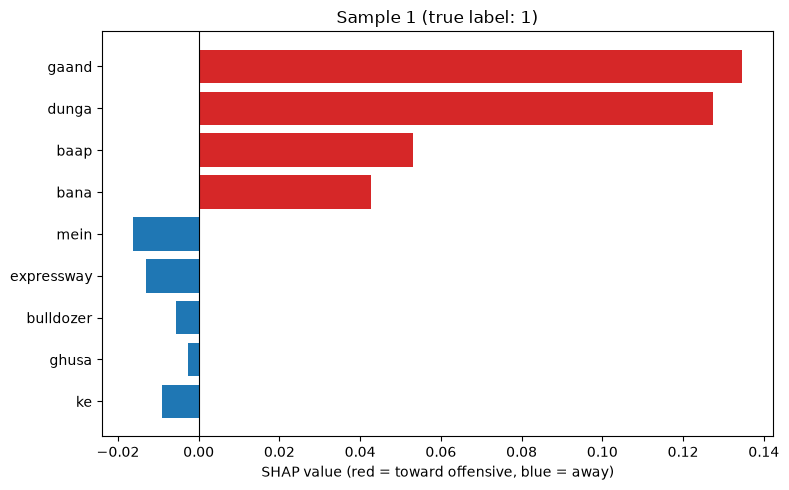

Saved plot to: D:\HINSAFE\results\shap_plots\sample_1_bar.png


PartitionExplainer explainer: 2it [00:10, 10.09s/it]               


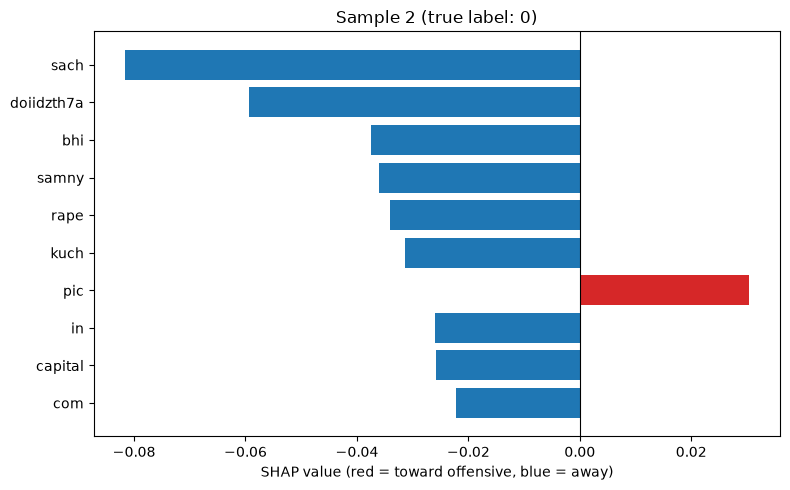

Saved plot to: D:\HINSAFE\results\shap_plots\sample_2_bar.png


PartitionExplainer explainer: 2it [00:19, 19.15s/it]               


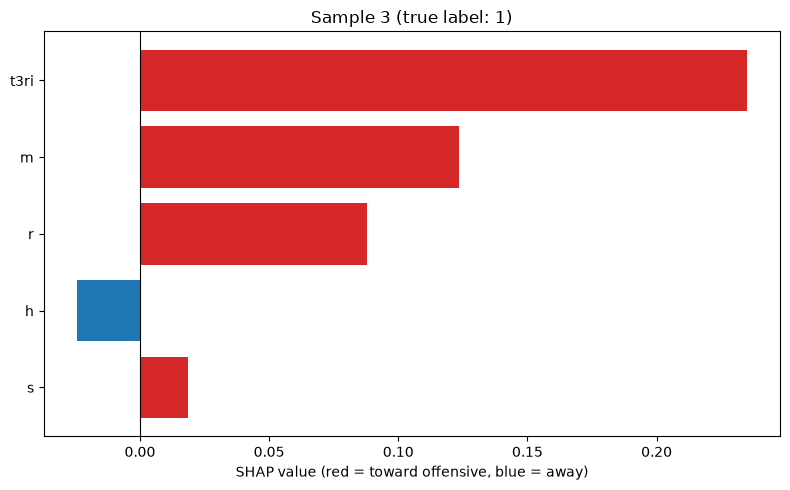

Saved plot to: D:\HINSAFE\results\shap_plots\sample_3_bar.png


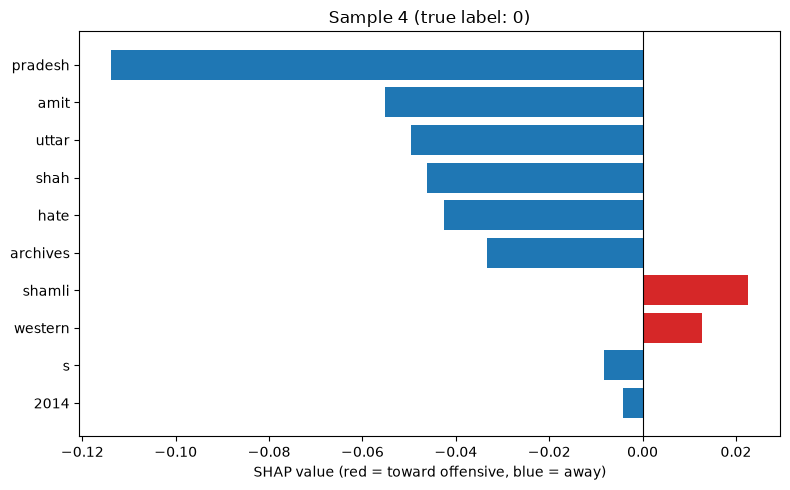

Saved plot to: D:\HINSAFE\results\shap_plots\sample_4_bar.png


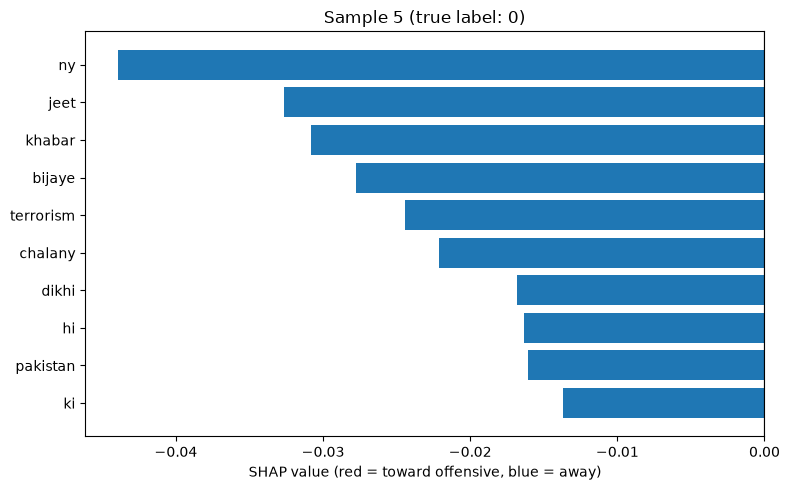

Saved plot to: D:\HINSAFE\results\shap_plots\sample_5_bar.png


PartitionExplainer explainer: 2it [00:23, 23.75s/it]               


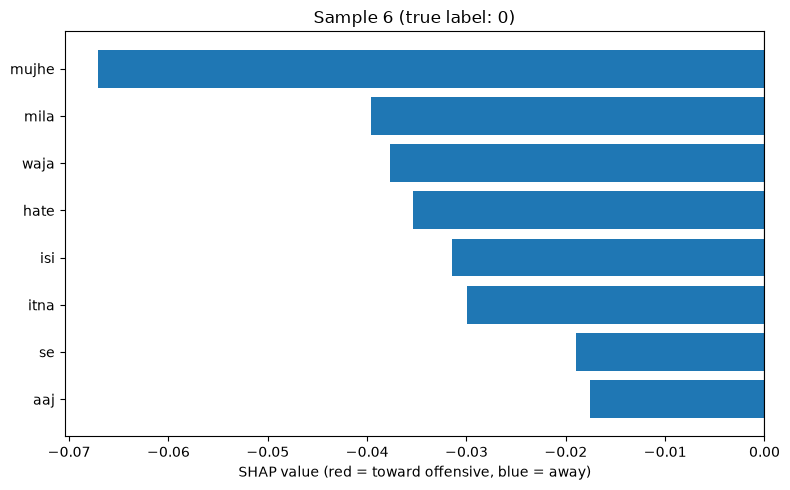

Saved plot to: D:\HINSAFE\results\shap_plots\sample_6_bar.png


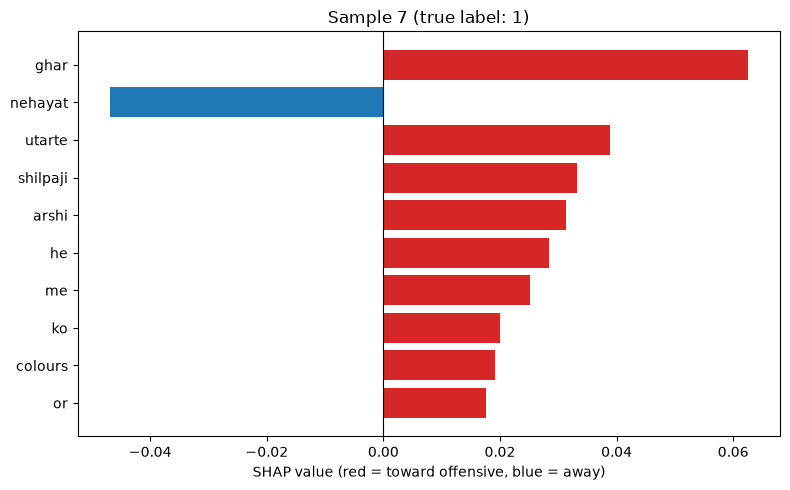

Saved plot to: D:\HINSAFE\results\shap_plots\sample_7_bar.png


PartitionExplainer explainer: 2it [00:41, 41.76s/it]               


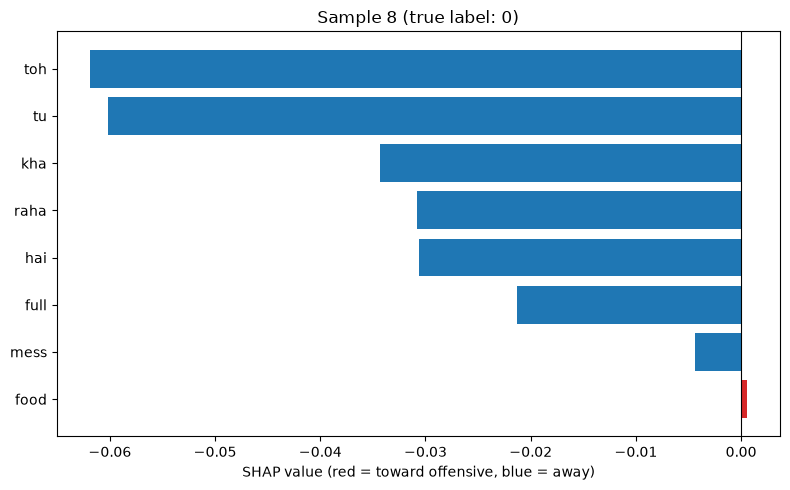

Saved plot to: D:\HINSAFE\results\shap_plots\sample_8_bar.png


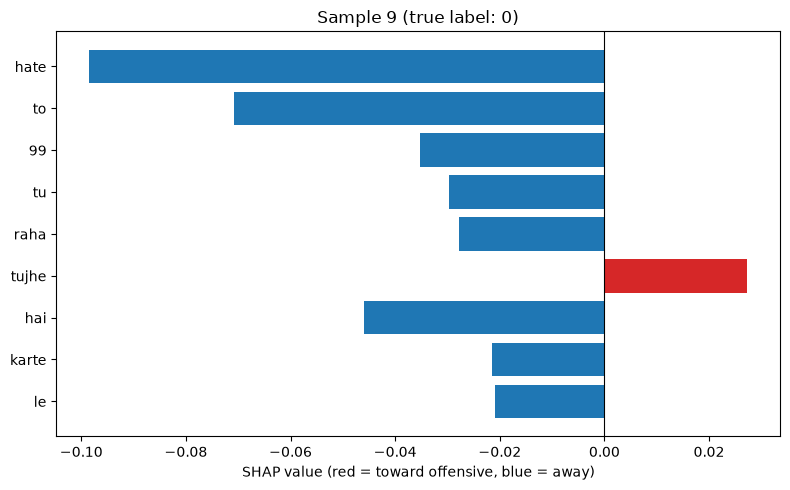

Saved plot to: D:\HINSAFE\results\shap_plots\sample_9_bar.png


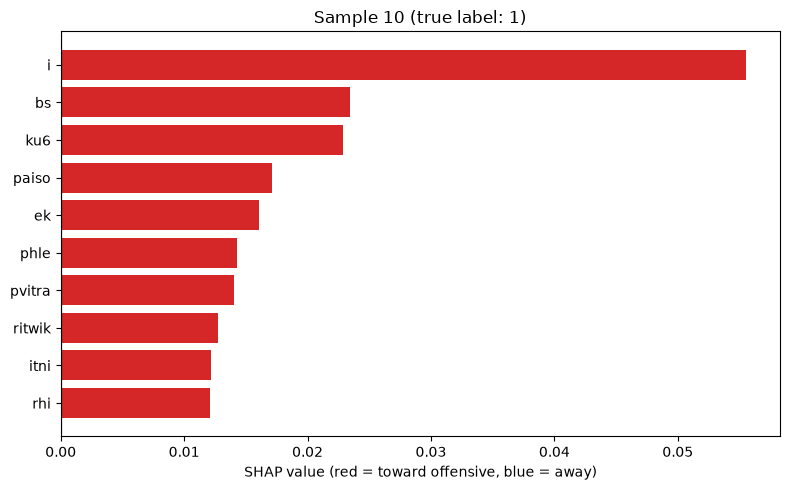

Saved plot to: D:\HINSAFE\results\shap_plots\sample_10_bar.png


PartitionExplainer explainer: 2it [00:40, 40.78s/it]               

Saved 10 explanations to: D:\HINSAFE\results\shap_plots


In [43]:
test_df = pd.read_csv(TEST_PATH)

sample_size = min(
    NUM_TEST_SAMPLES,
    len(test_df),
)

sample_df = (
    test_df
    .sample(sample_size, random_state=42)
    .reset_index(drop=True)
)

sample_texts = [
    basic_clean(text)
    for text in sample_df["text"].tolist()
]

sample_shap_values = explainer(sample_texts)

saved_outputs = []

for index, text in enumerate(sample_texts):
    explanation = sample_shap_values[
        index,
        :,
        "OFFENSIVE",
    ]

    # Save the text explanation as HTML.
    html_path = SHAP_DIR / f"sample_{index + 1}.html"

    html_output = shap.plots.text(
        explanation,
        display=False,
    )

    with html_path.open("w", encoding="utf-8") as file:
        file.write(str(html_output))

    # Save the bar chart.
    save_bar_chart(
        explanation=explanation,
        title=(
            f"Sample {index + 1} "
            f"(true label: {sample_df.loc[index, 'label']})"
        ),
        save_path=SHAP_DIR / f"sample_{index + 1}_bar.png",
    )

    # Save the structured analysis.
    saved_outputs.append(
        analyze_comment(
            sample_df.loc[index, "text"]
        )
    )

print(
    f"Saved {sample_size} explanations to: {SHAP_DIR}"
)

In [44]:
json_path = SHAP_DIR / "sample_outputs.json"

with json_path.open("w", encoding="utf-8") as file:
    json.dump(
        saved_outputs,
        file,
        indent=2,
        ensure_ascii=False,
    )

results_df = pd.DataFrame(saved_outputs)

print("Saved structured results to:", json_path)

results_df

Saved structured results to: D:\HINSAFE\results\shap_plots\sample_outputs.json


,comment,label,severity_score,severity_band,categories,flagged_words
0,tere baap ke gaand mein bulldozer ghusa ke exp...,1,81,HATE SPEECH,[],"{'gaand': 0.135, 'dunga': 0.128, 'baap': 0.053..."
1,matlab kuch bhi search rape capital in twitter...,0,20,SAFE,[],"{'pic': 0.03, 'twitter': 0.013}"
2,t3ri m r h s,1,81,HATE SPEECH,[],"{'t3ri': 0.235, 'm': 0.123, 'r': 0.088, 's': 0..."
3,2014 archives amit shah s hate speech in shaml...,0,24,SAFE,[],"{'shamli': 0.023, 'western': 0.013, 'in': 0.002}"
4,main terrorism k thekedaron ny pakistan ki jee...,0,23,SAFE,[],"{'twitter': 0.014, 'di': 0.009, 'k': 0.004, 't..."
5,isi waja se aaj itna hate mila mujhe,0,20,SAFE,[],{}
6,arshi ne hi paysa dia hoga ko or colours ko kh...,1,76,HATE SPEECH,[],"{'ghar': 0.063, 'utarte': 0.039, 'shilpaji': 0..."
7,tu toh full mess food kha raha hai,0,19,SAFE,[],{'food': 0.001}
8,tujhe to 99 log hate karte hai tu kab le raha hai,0,19,SAFE,[],{'tujhe': 0.027}
9,aasha n ritwik mere star me se ek the pvitra r...,1,81,HATE SPEECH,[],"{'i': 0.056, 'bs': 0.023, 'ku6': 0.023, 'paiso..."
